# H-N140 — H-N00 Dice+CE noSmooth

기본 H-N00에서 `loss.smooth`만 `0.00001 → 0.0`으로 바꾼 단일 변수 실험입니다. 네트워크, Dice+CE 비율, SGD, LR, batch, patch, sampling, epoch 및 early stopping은 H-N00과 동일합니다. 평가를 위해 매 epoch checkpoint, 5 epoch full-volume validation, Top-3 ±4 epoch 재검증을 적용합니다.

In [ ]:
from pathlib import Path
import json,subprocess,time
import pandas as pd
from IPython.display import clear_output,display
ROOT=Path("/home/stu03/workspace/model");DATA_ROOT=Path("/home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet");RESULTS_ROOT=ROOT/"runs/nnunet";RUNNER=ROOT/"scripts/training/run_h_n140.py"
FOLD_DIR=RESULTS_ROOT/"Dataset001_ICHBinary/nnUNetTrainerICHBaseline__ICHPlansBaselineDiceCENoSmoothV1__3d_fullres/fold_0";PROGRESS_FILE=FOLD_DIR/"progress.json";RUN_DIR=ROOT/"runs/batches/H-N140";LOG_FILE=RUN_DIR/"train.log";PID_FILE=RUN_DIR/"train.pid"
print(RUNNER.exists(),RUNNER);print(FOLD_DIR)

True /home/stu03/workspace/model/scripts/training/run_h_n140.py
/home/stu03/workspace/model/runs/nnunet/Dataset001_ICHBinary/nnUNetTrainerICHBaseline__ICHPlansBaselineDiceCENoSmoothV1__3d_fullres/fold_0


## 1. H-N00과 설정 차이 확인

In [ ]:
import yaml
base=yaml.safe_load((ROOT/"configs/experiments/hemorrhage/H-N00.yaml").read_text());trial=yaml.safe_load((ROOT/"configs/experiments/hemorrhage/H-N140.yaml").read_text())
print("H-N00 smooth:",base["loss"]["smooth"]);print("H-N140 smooth:",trial["loss"]["smooth"]);print("H-N140 loss:",trial["loss"])

H-N00 smooth: 1e-05
H-N140 smooth: 0.0
H-N140 loss: {'name': 'dice_ce', 'include_background': False, 'dice_weight': 1.0, 'ce_weight': 1.0, 'smooth': 0.0}


## 2. GPU 및 dry-run

In [ ]:
subprocess.run(["nvidia-smi"],check=False)
command=[str(ROOT/".venv/bin/python"),str(RUNNER),"--data-root",str(DATA_ROOT),"--results-root",str(RESULTS_ROOT),"--gpu","0"]
subprocess.run(command+["--dry-run"],cwd=ROOT,check=True)

Mon Sep  7 07:09:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
| 38%   48C    P8             15W /  575W |   13164MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CompletedProcess(args=['/home/stu03/workspace/model/.venv/bin/python', '/home/stu03/workspace/model/scripts/training/run_h_n140.py', '--data-root', '/home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet', '--results-root', '/home/stu03/workspace/model/runs/nnunet', '--gpu', '0', '--dry-run'], returncode=0)

## 3. 백그라운드 학습 시작/자동 재개

In [ ]:
def pid_is_running(path):
 if not path.is_file():return False
 try:
  pid=path.read_text().strip();stat=subprocess.run(["ps","-o","stat=","-p",pid],capture_output=True,text=True).stdout.strip();return bool(stat) and not stat.startswith("Z")
 except (ValueError,OSError):return False
RUN_DIR.mkdir(parents=True,exist_ok=True)
if pid_is_running(PID_FILE):print("이미 실행 중 PID:",PID_FILE.read_text().strip())
else:
 log=LOG_FILE.open("a",encoding="utf-8");process=subprocess.Popen(command,cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,start_new_session=True);PID_FILE.write_text(str(process.pid));print("시작 PID:",process.pid)

시작 PID: 3625600


## 4. 실시간 진행률

In [ ]:
def read_json(path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def fmt(seconds):
    if seconds is None:
        return "-"
    seconds = int(seconds)
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"

def pid_is_running(path):
    if not path.is_file():
        return False
    try:
        pid = path.read_text(encoding="utf-8").strip()
        stat = subprocess.run(
            ["ps", "-o", "stat=", "-p", pid],
            capture_output=True, text=True,
        ).stdout.strip()
        return bool(stat) and not stat.startswith("Z")
    except (ValueError, OSError):
        return False

BEST_FULL_FILE = FOLD_DIR / "best_full_macro.json"

while True:
    clear_output(wait=True)
    progress = read_json(PROGRESS_FILE)
    running = pid_is_running(PID_FILE)
    training_status = progress.get("status")

    if running and training_status in {"completed", "early_stopped"}:
        phase = "top3_neighborhood_validation"
        display_status = "running"
    elif running:
        phase = "training"
        display_status = training_status or "starting"
    elif BEST_FULL_FILE.is_file():
        phase = "completed"
        display_status = "completed"
    elif progress:
        phase = "stopped_or_failed"
        display_status = training_status or "stopped"
    else:
        phase = "waiting"
        display_status = "waiting"

    row = {
        "실험": "H-N140",
        "상태": display_status,
        "Phase": phase,
        "Epoch": f"{progress.get('current_epoch', 0)}/{progress.get('total_epochs', '-')}",
        "진행률(%)": progress.get("progress_percent", 0),
        "ETA": fmt(progress.get("eta_seconds")),
        "Train Loss": progress.get("train_loss"),
        "Dice": progress.get("pseudo_dice"),
        "Recall": progress.get("pseudo_recall"),
        "Composite": progress.get("composite"),
        "Best Dice": progress.get("best_dice"),
        "Best Recall": progress.get("best_recall"),
        "Best Composite": progress.get("best_composite"),
        "Full Macro Dice": progress.get("full_macro_dice"),
        "Best Full Macro Dice": progress.get("best_full_macro_dice"),
        "Best Epoch": progress.get("best_full_macro_epoch"),
        "Top-3": progress.get("top_full_macro_epochs"),
        "보존 checkpoint": progress.get("retained_epoch_checkpoints"),
        "GPU(GB)": progress.get("gpu_max_memory_gb"),
        "PID 실행 중": running,
    }
    display(pd.DataFrame([row]))

    if LOG_FILE.is_file():
        print("로그 마지막 10줄:")
        print("".join(LOG_FILE.read_text(encoding="utf-8", errors="replace").splitlines(True)[-10:]))

    if not running and progress:
        break
    time.sleep(10)


,실험,상태,Phase,Epoch,진행률(%),ETA,Train Loss,Dice,Recall,Composite,Best Dice,Best Recall,Best Composite,Full Macro Dice,Best Full Macro Dice,Best Epoch,Top-3,보존 checkpoint,GPU(GB),PID 실행 중
0,H-N140,early_stopped,stopped_or_failed,299/1000,29.9,05:54:21,-0.470647,0.721114,0.70435,0.712732,0.834378,0.871323,0.834277,0.604374,0.604374,295,"[295, 265, 155]",27,10.936,False


로그 마지막 10줄:
2026-09-07 11:06:35.543563: Pruning: composite가 patience 동안 개선되지 않아 조기 종료합니다.
2026-09-07 11:06:35.680984: Training done.
Traceback (most recent call last):
  File "/home/stu03/workspace/model/scripts/validation/evaluate_h_n140_neighborhood.py", line 43, in <module>
    if __name__=="__main__":raise SystemExit(main())
                                             ^^^^^^
  File "/home/stu03/workspace/model/scripts/validation/evaluate_h_n140_neighborhood.py", line 22, in main
    fold=a.results_root.resolve()/f"Dataset{int(e['dataset_id']):03d}_{e['dataset_name']}"/f"nnUNetTrainerICHBaseline__{q['output_identifier']}__{e['configuration']}"/f"fold_{e['fold']}";hp=fold/"full_validation_history.json"
                                                                       ~^^^^^^^^^^^^^^^^
KeyError: 'dataset_name'



## 5. 완료 결과

In [9]:
print("output:",FOLD_DIR)
for name in ["checkpoint_best_composite.pth","checkpoint_final.pth","validation/summary.json"]:print(name,(FOLD_DIR/name).exists())

output: /home/stu03/workspace/model/runs/nnunet/Dataset001_ICHBinary/nnUNetTrainerICHBaseline__ICHPlansBaselineDiceCENoSmoothV1__3d_fullres/fold_0
checkpoint_best_composite.pth True
checkpoint_final.pth True
validation/summary.json False


## 6. Full-volume Macro Dice Best 확인

5 epoch마다 계산된 양성 환자 기준 Full Macro Dice 전체 기록을 확인합니다. 학습 중에는 현재까지의 provisional best이며, 학습 종료 후 Top-3 주변 재검증까지 끝나면 `best_full_macro.json`의 최종 best를 표시합니다.

In [15]:
HISTORY_FILE = FOLD_DIR / "full_validation_history.json"
BEST_MACRO_FILE = FOLD_DIR / "best_full_macro.json"

history = read_json(HISTORY_FILE)
final_best = read_json(BEST_MACRO_FILE)

if not history:
    print("아직 5-epoch full-volume validation 결과가 없습니다.")
else:
    macro_history_df = pd.DataFrame(history).sort_values("epoch")
    ranked_df = macro_history_df.sort_values(
        "macro_dice_positive", ascending=False
    ).reset_index(drop=True)
    ranked_df.index = ranked_df.index + 1

    current_best = ranked_df.iloc[0]
    print("현재 Best Macro Dice:", f"{current_best['macro_dice_positive']:.6f}")
    print("현재 Best Epoch     :", int(current_best["epoch"]))
    print("검증 완료 epoch 수  :", len(macro_history_df))
    top3_epochs = ranked_df.head(3)["epoch"].astype(int).tolist()
    neighborhood_epochs = sorted({
        epoch
        for anchor in top3_epochs
        for epoch in range(max(1, anchor - 4), min(1000, anchor + 4) + 1)
    })
    checkpoint_dir = FOLD_DIR / "epoch_checkpoints"
    available_neighbors = [
        epoch for epoch in neighborhood_epochs
        if (checkpoint_dir / f"checkpoint_epoch_{epoch:04d}.pth").is_file()
    ]
    evaluated_neighbors = [
        epoch for epoch in neighborhood_epochs
        if (FOLD_DIR / "full_validation" / f"epoch_{epoch:04d}" / "summary.json").is_file()
    ]
    print("현재 Top-3          :", top3_epochs)
    print("Top-3 ±4 예정 epoch :", neighborhood_epochs)
    print("보존 checkpoint     :", available_neighbors)
    print("주변 검증 완료 epoch:", evaluated_neighbors)

    if final_best:
        print()
        print("Top-3 주변 재검증 최종 Best")
        print("Final Best Macro Dice:", f"{float(final_best['macro_dice_positive']):.6f}")
        print("Final Best Epoch     :", int(final_best["epoch"]))

    display(
        ranked_df[["epoch", "macro_dice_positive", "positive_cases"]]
        .head(10)
        .rename(columns={
            "epoch": "Epoch",
            "macro_dice_positive": "Full Macro Dice",
            "positive_cases": "Positive Cases",
        })
    )

현재 Best Macro Dice: 0.604374
현재 Best Epoch     : 295
검증 완료 epoch 수  : 83
현재 Top-3          : [295, 265, 155]
Top-3 ±4 예정 epoch : [151, 152, 153, 154, 155, 156, 157, 158, 159, 261, 262, 263, 264, 265, 266, 267, 268, 269, 291, 292, 293, 294, 295, 296, 297, 298, 299]
보존 checkpoint     : [151, 152, 153, 154, 155, 156, 157, 158, 159, 261, 262, 263, 264, 265, 266, 267, 268, 269, 291, 292, 293, 294, 295, 296, 297, 298, 299]
주변 검증 완료 epoch: [151, 152, 153, 154, 155, 156, 157, 158, 159, 261, 262, 263, 264, 265, 266, 267, 268, 269, 291, 292, 293, 294, 295, 296, 297, 298, 299]

Top-3 주변 재검증 최종 Best
Final Best Macro Dice: 0.604374
Final Best Epoch     : 295


,Epoch,Full Macro Dice,Positive Cases
1,295,0.604374,35
2,265,0.602987,35
3,155,0.600237,35
4,266,0.599798,35
5,262,0.597238,35
6,190,0.596063,35
7,245,0.595390,35
8,151,0.594613,35
9,297,0.593608,35
10,240,0.593073,35


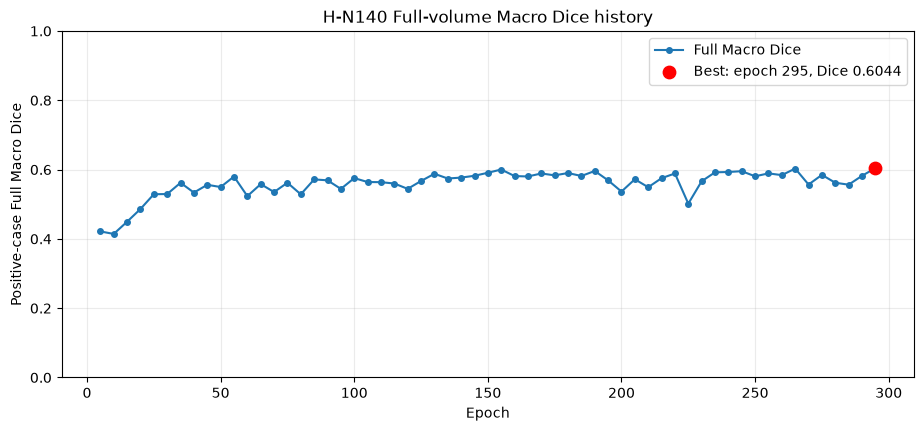

In [11]:
# Full Macro Dice 학습 추이
if history:
    import matplotlib.pyplot as plt

    plot_df = macro_history_df.sort_values("epoch")
    best_row = plot_df.loc[plot_df["macro_dice_positive"].idxmax()]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(
        plot_df["epoch"],
        plot_df["macro_dice_positive"],
        marker="o",
        markersize=4,
        linewidth=1.5,
        label="Full Macro Dice",
    )
    ax.scatter(
        [best_row["epoch"]],
        [best_row["macro_dice_positive"]],
        color="red",
        s=80,
        zorder=3,
        label=(
            f"Best: epoch {int(best_row['epoch'])}, "
            f"Dice {best_row['macro_dice_positive']:.4f}"
        ),
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Positive-case Full Macro Dice")
    ax.set_ylim(0, 1)
    ax.set_title("H-N140 Full-volume Macro Dice history")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()